# S3 data usage — August 2026

Mirrors `explore_s3_usage.ipynb` but uses the **2026-08-02** weekly_report snapshot.
A comparison section at the end shows deltas vs the **2026-06-28** snapshot cached in `weekly_report.parquet`.

## Running this notebook

Pick the project `.venv` as the kernel (Select Kernel -> Jupyter Kernel -> "S3 data use exploration (.venv)"). The cells below read the cached `weekly_report_2026-08-02.parquet` so they run offline. To refresh from source: run `aws sso login --profile aind_prod_sso`, then re-query with `use_cache=False`.

In [1]:
import pandas as pd

import s3_data_use as s3

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)
pd.options.display.float_format = "{:,.2f}".format

NEW_PARQUET = "weekly_report_2026-08-02.parquet"
OLD_PARQUET = "weekly_report.parquet"          # 2026-06-28 snapshot

df = s3.load_weekly_report(parquet_path=NEW_PARQUET)
df = s3.add_category(df)
print(f"{len(df):,} rows, {df['prefix'].nunique():,} prefixes, {df['size_tb'].sum():,.0f} TB, {df['category'].nunique()} categories")
print(f"report_date: {df['report_date'].unique()}")

2,984,299 rows, 155,799 prefixes, 32,408 TB, 252 categories
report_date: <ArrowStringArray>
['2026-08-02T01-00Z']
Length: 1, dtype: string


## Size by bucket

In [2]:
s3.size_by_bucket(df)

,total_tb
bucket,
aind-open-data,"21,414.40"
codeocean-s3resultsbucket-1182nktl2bh9f,"3,943.13"
aind-scratch-data,"1,893.81"
aind-archive,"1,846.75"
codeocean-s3datasetsbucket-1u41qdg42ur9,"1,755.07"
codeocean-s3batchbucket-16itpvq060udk,809.89
aind-private-data-prod-o5171v,552.91
aind-msma-morphology-data,91.58
aind-ephys-data,49.96


## Size by category

In [3]:
s3.size_by_category(df)

,total_tb,n_prefixes
category,,
exaSPIM,"10,351.67",997
SmartSPIM,"7,407.21",9381
multiplane-ophys,"2,006.94",5796
codeocean-pipeline (private/unresolved),"1,936.58",987
HCR,"1,413.24",3234
codeocean-dataset (unresolved),"1,080.65",59772
timwang,"1,024.58",1
rachel.dalley,900.08,1
behavior,769.45,36692


In [4]:
(
    df[df["category"] == "other categories"]
    .groupby("prefix", as_index=False)["size_tb"].sum()
    .sort_values("size_tb", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

,prefix,size_tb
0,826507_2026-05-29_16-56-55_processed_2026-06-24_11-46-02,56.37
1,826507_2026-05-29_16-56-55,45.94
2,828408_2025-11-13_10-30-53_motion-corrected_2026-05-12_16-55-09,2.88
3,828408_2025-11-13_10-30-53_motioncorrected_2026-04-26_01-06-17,2.88
4,794495_alignments,0.70
5,786400_alignment,0.37
6,837963_2026-05-09_19-10-02_motion-corrected_2026-05-12_09-44-12,0.29
7,837963_2026-05-09_19-10-02_motion-corrected_2026-05-12_01-52-53,0.29
8,826507_2026-05-29_16-56-55_processed_2026-06-15_12-24-01,0.24
9,664761_alignment,0.23


In [5]:
df[df["prefix"] == "841322_2026-03-19_18-56-42"][
    ["bucket", "subprefix", "storage_class", "size_in_bytes", "size_tb", "number_of_files"]
].sort_values("size_tb", ascending=False)

,bucket,subprefix,storage_class,size_in_bytes,size_tb,number_of_files
329520,aind-open-data,841322_2026-03-19_18-56-42/ecephys,INTELLIGENT_TIERING,76756681914589,76.76,12291925
326803,aind-open-data,841322_2026-03-19_18-56-42/behavior-videos,INTELLIGENT_TIERING,4076318394443,4.08,6290
249361,aind-open-data,841322_2026-03-19_18-56-42/behavior-videos,INTELLIGENT_TIERING,467482215254,0.47,692
437585,aind-open-data,841322_2026-03-19_18-56-42/behavior,INTELLIGENT_TIERING,243914631432,0.24,12574
367209,aind-open-data,841322_2026-03-19_18-56-42/behavior,INTELLIGENT_TIERING,26674560994,0.03,1381
400538,aind-open-data,841322_2026-03-19_18-56-42/behavior,STANDARD,302685418,0.00,9542
406478,aind-open-data,841322_2026-03-19_18-56-42/ecephys,STANDARD,507618,0.00,1756
528979,aind-open-data,841322_2026-03-19_18-56-42/original_metadata,STANDARD,89794,0.00,10
310922,aind-open-data,841322_2026-03-19_18-56-42/metadata.nd.json,STANDARD,52288,0.00,1
96444,aind-open-data,841322_2026-03-19_18-56-42/instrument.json,STANDARD,18562,0.00,1


## Category by bucket (main view)

TB by category (rows) x bucket (columns). Bucket columns are ordered by total size (largest on the left); category rows sorted by `aind-open-data`.

In [6]:
s3.category_by_bucket(df, sort_bucket="aind-open-data")

bucket,aind-open-data,codeocean-s3resultsbucket-1182nktl2bh9f,aind-scratch-data,aind-archive,codeocean-s3datasetsbucket-1u41qdg42ur9,codeocean-s3batchbucket-16itpvq060udk,aind-private-data-prod-o5171v,aind-msma-morphology-data,aind-ephys-data,aind-ophys-data,aind-behavior-data,aind-private-scratch-data-prod-o5171v,aind-open-data-prod-o5171v,TOTAL
category,,,,,,,,,,,,,,
exaSPIM,"10,202.10",25.32,123.18,0.00,0.00,0.96,0.00,0.10,0.00,0.00,0.00,0.00,0.00,"10,351.67"
SmartSPIM,"6,908.00",54.04,130.03,0.00,0.00,312.57,0.58,0.00,0.00,0.00,0.00,0.00,1.98,"7,407.21"
HCR,"1,387.83",22.16,2.65,0.00,0.00,0.60,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"1,413.24"
multiplane-ophys,704.21,"1,022.44",173.19,0.00,0.00,6.70,100.40,0.00,0.00,0.00,0.00,0.00,0.00,"2,006.94"
behavior,465.66,62.62,41.32,3.30,0.00,0.10,195.43,0.00,0.00,0.00,1.03,0.00,0.00,769.45
fMOST,380.99,0.00,0.00,0.00,0.00,0.00,0.00,20.46,0.00,0.00,0.00,0.00,0.00,401.44
Information Foraging,360.46,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,360.46
ecephys,243.50,85.75,1.05,0.06,0.00,165.93,167.79,0.00,49.95,0.00,0.00,0.00,0.00,714.04
Single-neuron computations within brain-wide circuits (SCBC) - SLAP2,171.96,0.00,0.00,0.00,0.36,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,172.32


## Reprocessing waste (aind-open-data)

Storage held by superseded reprocessing runs — same analysis as the June notebook.

In [7]:
rep = s3.reprocessing_table(df, bucket="aind-open-data")
s3.reprocessing_summary(rep).to_frame("value")

,value
derived_assets,"17,482.00"
derived_tb,"9,507.10"
raw+process_groups,"11,900.00"
groups_reprocessed,"3,200.00"
pct_groups_reprocessed,26.90
redundant_runs,"5,582.00"
raw_assets_affected,"2,814.00"
reclaimable_tb,"2,608.60"


### Redundant reprocessing: by modality and by rerun count

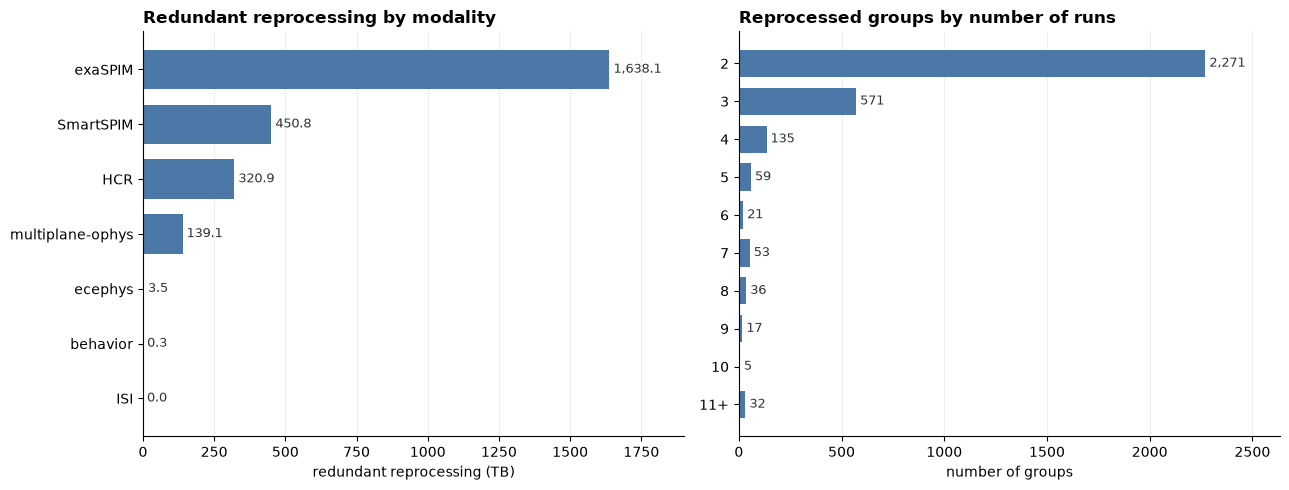

In [8]:
import matplotlib.pyplot as plt

BAR = "#4C78A8"

def _barh(ax, series, title, xlabel, valfmt="{:,.0f}"):
    s = series.iloc[::-1]
    ax.barh(s.index.astype(str), s.values, color=BAR, height=0.72)
    for y, v in enumerate(s.values):
        ax.text(v, y, " " + valfmt.format(v), va="center", ha="left", fontsize=9, color="#333")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#eee")
    ax.set_axisbelow(True)
    ax.margins(x=0.16)

by_mod = s3.reclaimable_by(rep, "modality", top_n=None)["reclaimable_tb"]
by_mod = by_mod[by_mod.index != "(unlabeled)"].head(10)

dist = s3.rerun_distribution(rep)["n_groups"]
reproc = dist[dist.index >= 2]
bars = reproc[reproc.index <= 10]
runs = pd.Series(
    list(bars.values) + [int(reproc[reproc.index >= 11].sum())],
    index=[str(i) for i in bars.index] + ["11+"],
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
_barh(axes[0], by_mod, "Redundant reprocessing by modality", "redundant reprocessing (TB)", valfmt="{:,.1f}")
_barh(axes[1], runs, "Reprocessed groups by number of runs", "number of groups")
fig.tight_layout()
plt.show()

### Top cleanup targets

In [9]:
s3.top_offenders(rep, top_n=15)

,input,process_norm,reclaimable_tb,runs
0,exaSPIM_784896_2025-08-19_10-48-12,processed,102.38,14
1,exaSPIM_794492_2026-01-09_16-50-40,processed,91.35,2
2,exaSPIM_721332_2025-04-05_14-48-36,flatfield-correction_fusion,67.40,3
3,exaSPIM_794491_2025-10-21_12-31-25,processed,67.14,3
4,exaSPIM_660525_2025-12-12_18-53-11,processed,63.12,2
5,exaSPIM_794495_2026-01-21_14-25-07,processed,61.05,3
6,exaSPIM_784802_2025-09-10_17-08-56,processed,58.11,15
7,exaSPIM_784666_2025-07-25_17-36-18,processed,54.38,6
8,HCR_831990_2026-05-11_00-00-00,processed,52.85,10
9,HCR_831990-s6-r2_2026-06-23_00-00-06,processed,52.24,7


---
## Comparison: August 2 vs June 28

Loads the June 28 snapshot (`weekly_report.parquet`) and computes delta vs the August 2 data. Positive delta = growth.

In [10]:
from pathlib import Path

if not Path(OLD_PARQUET).exists():
    print(f"Old parquet not found at {OLD_PARQUET} — skipping comparison cells.")
else:
    df_old = s3.load_weekly_report(parquet_path=OLD_PARQUET)
    df_old = s3.add_category(df_old)
    old_date = df_old["report_date"].iloc[0] if "report_date" in df_old.columns else "(unknown)"
    new_date = df["report_date"].iloc[0] if "report_date" in df.columns else "(unknown)"
    print(f"Old: {old_date}  |  rows: {len(df_old):,}  |  {df_old['prefix'].nunique():,} prefixes  |  {df_old['size_tb'].sum():,.0f} TB")
    print(f"New: {new_date}  |  rows: {len(df):,}  |  {df['prefix'].nunique():,} prefixes  |  {df['size_tb'].sum():,.0f} TB")
    print(f"Delta: {df['size_tb'].sum() - df_old['size_tb'].sum():+,.0f} TB  ({(df['size_tb'].sum() / df_old['size_tb'].sum() - 1) * 100:+.1f}%)")

Old: 2026-06-28T01-00Z  |  rows: 2,817,972  |  142,032 prefixes  |  30,104 TB
New: 2026-08-02T01-00Z  |  rows: 2,984,299  |  155,799 prefixes  |  32,408 TB
Delta: +2,304 TB  (+7.7%)


### Bucket comparison

In [11]:
if Path(OLD_PARQUET).exists():
    buckets_old = s3.size_by_bucket(df_old).rename(columns={"total_tb": "jun28_tb"})
    buckets_new = s3.size_by_bucket(df).rename(columns={"total_tb": "aug02_tb"})
    cmp_buckets = buckets_new.join(buckets_old, how="outer").fillna(0)
    cmp_buckets["delta_tb"] = cmp_buckets["aug02_tb"] - cmp_buckets["jun28_tb"]
    cmp_buckets["delta_pct"] = ((cmp_buckets["aug02_tb"] / cmp_buckets["jun28_tb"].replace(0, float("nan"))) - 1) * 100
    cmp_buckets = cmp_buckets.sort_values("aug02_tb", ascending=False)
    cmp_buckets

### Category comparison (top 25 by August size)

In [12]:
if Path(OLD_PARQUET).exists():
    cats_old = s3.size_by_category(df_old, top_n=None)["total_tb"].rename("jun28_tb")
    cats_new = s3.size_by_category(df, top_n=None)["total_tb"].rename("aug02_tb")
    cmp_cats = pd.concat([cats_new, cats_old], axis=1).fillna(0)
    cmp_cats["delta_tb"] = cmp_cats["aug02_tb"] - cmp_cats["jun28_tb"]
    cmp_cats["delta_pct"] = ((cmp_cats["aug02_tb"] / cmp_cats["jun28_tb"].replace(0, float("nan"))) - 1) * 100
    cmp_cats.sort_values("aug02_tb", ascending=False).head(25)

### Fastest-growing categories (by absolute delta TB)

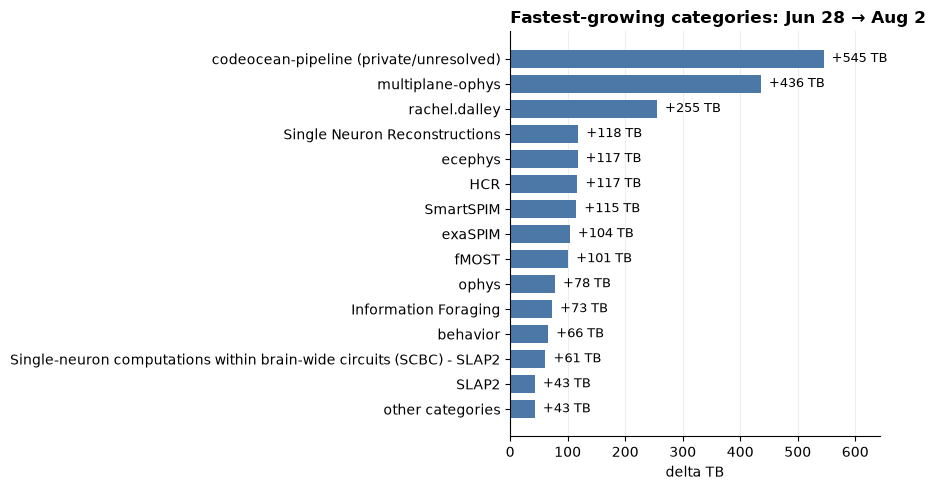

In [13]:
if Path(OLD_PARQUET).exists():
    top_growth = cmp_cats.sort_values("delta_tb", ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ["#d62728" if v < 0 else "#4C78A8" for v in top_growth["delta_tb"].iloc[::-1].values]
    ax.barh(top_growth.index[::-1].astype(str), top_growth["delta_tb"].iloc[::-1].values, color=colors, height=0.72)
    for y, v in enumerate(top_growth["delta_tb"].iloc[::-1].values):
        ax.text(max(v, 0), y, f"  {v:+,.0f} TB", va="center", ha="left", fontsize=9)
    ax.set_title("Fastest-growing categories: Jun 28 → Aug 2", loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel("delta TB")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#eee")
    ax.set_axisbelow(True)
    ax.margins(x=0.18)
    plt.tight_layout()
    plt.show()

### Fastest-growing categories in aind-open-data

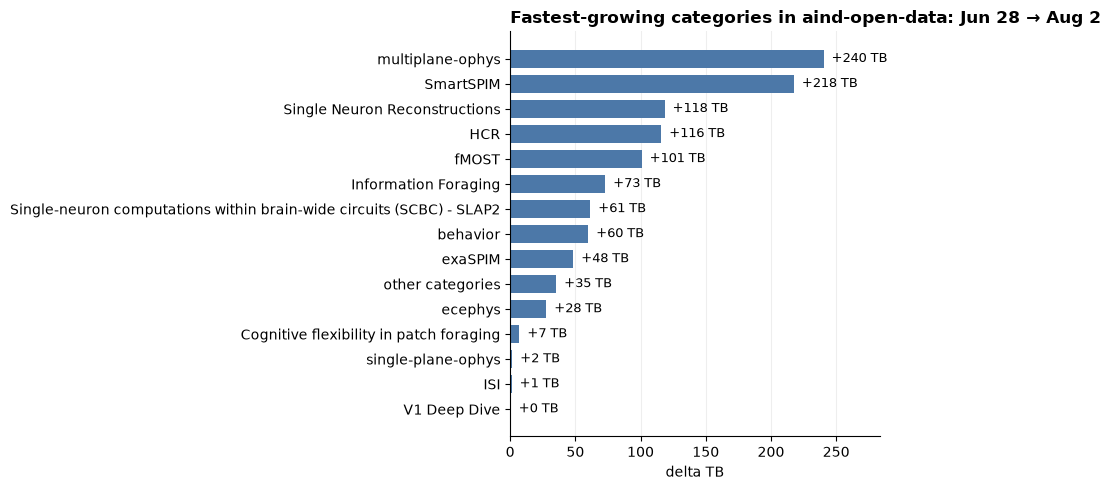

In [16]:
if Path(OLD_PARQUET).exists():
    od_old = df_old[df_old["bucket"] == "aind-open-data"].groupby("category")["size_tb"].sum().rename("jun28_tb")
    od_new = df[df["bucket"] == "aind-open-data"].groupby("category")["size_tb"].sum().rename("aug02_tb")
    cmp_od = pd.concat([od_new, od_old], axis=1).fillna(0)
    cmp_od["delta_tb"] = cmp_od["aug02_tb"] - cmp_od["jun28_tb"]
    top_od = cmp_od.sort_values("delta_tb", ascending=False).head(15)

    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ["#d62728" if v < 0 else "#4C78A8" for v in top_od["delta_tb"].iloc[::-1].values]
    ax.barh(top_od.index[::-1].astype(str), top_od["delta_tb"].iloc[::-1].values, color=colors, height=0.72)
    for y, v in enumerate(top_od["delta_tb"].iloc[::-1].values):
        ax.text(max(v, 0), y, f"  {v:+,.0f} TB", va="center", ha="left", fontsize=9)
    ax.set_title("Fastest-growing categories in aind-open-data: Jun 28 → Aug 2", loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel("delta TB")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#eee")
    ax.set_axisbelow(True)
    ax.margins(x=0.18)
    plt.tight_layout()
    plt.show()

### Gross additions vs deletions by category (aind-open-data)

Breaks the net delta into two components: TB from entirely new prefixes (right, blue) and TB from prefixes that existed in June but are gone by August (left, orange). Categories follow the same order as the net-growth chart above.

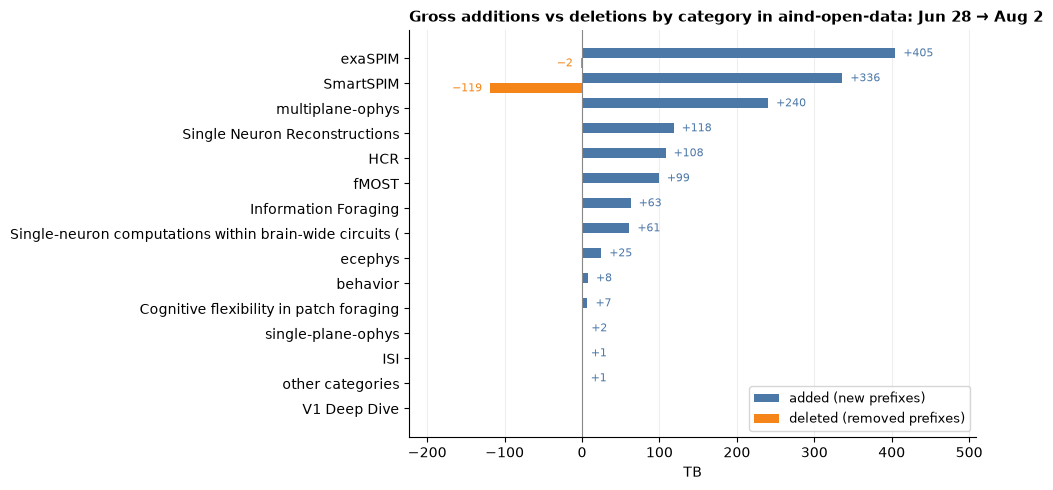


Summary (aind-open-data only):
  Gross added:   1,474.6 TB  (41 categories)
  Gross deleted: 120.3 TB  (3 categories)


In [18]:
if Path(OLD_PARQUET).exists():
    od_mask = df["bucket"] == "aind-open-data"
    od_mask_old = df_old["bucket"] == "aind-open-data"

    # gross additions: new prefixes in aind-open-data, sized and categorised from August df
    added_od = (
        df[od_mask & df["prefix"].isin(added)]
        .groupby("category")["size_tb"].sum()
        .rename("added_tb")
    )
    # gross deletions: removed prefixes in aind-open-data, sized and categorised from June df
    removed_od = (
        df_old[od_mask_old & df_old["prefix"].isin(removed)]
        .groupby("category")["size_tb"].sum()
        .rename("deleted_tb")
    )

    butterfly = pd.concat([added_od, removed_od], axis=1).fillna(0)
    butterfly = butterfly.reindex(top_od.index).fillna(0)
    butterfly = butterfly.sort_values("added_tb", ascending=True)  # ascending so largest ends up on top

    fig, ax = plt.subplots(figsize=(10, 5))
    ys = range(len(butterfly))
    labels = [t[:55] for t in butterfly.index.astype(str)]

    ax.barh(list(ys), butterfly["added_tb"].values, height=0.4, align="edge",
            color="#4C78A8", label="added (new prefixes)")
    ax.barh(list(ys), -butterfly["deleted_tb"].values, height=-0.4, align="edge",
            color="#F58518", label="deleted (removed prefixes)")

    for y, (add, rem) in enumerate(zip(butterfly["added_tb"], butterfly["deleted_tb"])):
        if add > 0.5:
            ax.text(add, y + 0.2, f"  +{add:,.0f}", va="center", ha="left", fontsize=8, color="#4C78A8")
        if rem > 0.5:
            ax.text(-rem, y - 0.2, f"−{rem:,.0f}  ", va="center", ha="right", fontsize=8, color="#F58518")

    ax.set_yticks(list(ys))
    ax.set_yticklabels(labels)
    ax.axvline(0, color="#888", linewidth=0.8)
    ax.set_xlabel("TB")
    ax.set_title("Gross additions vs deletions by category in aind-open-data: Jun 28 → Aug 2",
                 loc="left", fontsize=11, fontweight="bold")
    ax.legend(loc="lower right", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#eee")
    ax.set_axisbelow(True)
    ax.margins(x=0.2, y=0.05)
    plt.tight_layout()
    plt.show()

    print("\nSummary (aind-open-data only):")
    print(f"  Gross added:   {butterfly['added_tb'].sum():,.1f} TB  ({len(added_od[added_od > 0])} categories)")
    print(f"  Gross deleted: {butterfly['deleted_tb'].sum():,.1f} TB  ({len(removed_od[removed_od > 0])} categories)")

### New prefixes (in August but not June)

Assets that appear in the August snapshot but were absent from June — net-new acquisitions or reprocessing outputs.

In [15]:
if Path(OLD_PARQUET).exists():
    old_prefixes = set(df_old["prefix"].dropna().unique())
    new_prefixes = set(df["prefix"].dropna().unique())
    added = new_prefixes - old_prefixes
    removed = old_prefixes - new_prefixes
    print(f"Prefixes added since Jun 28:   {len(added):,}")
    print(f"Prefixes removed since Jun 28: {len(removed):,}")

    # Size of added prefixes by category
    added_df = df[df["prefix"].isin(added)].copy()
    added_df.groupby("category")["size_tb"].sum().sort_values(ascending=False).head(20).to_frame("added_tb")

Prefixes added since Jun 28:   14,373
Prefixes removed since Jun 28: 606
